In [ ]:
# === Install ===
!pip -q install open_clip_torch scikit-learn matplotlib pandas tqdm
!pip -q install --upgrade "open_clip_torch>=2.24.0" "timm>=0.9.16"

# -*- coding: utf-8 -*-
"""
ViT-L/16 SigLIP2-384 — Linear Probe + (opzionale) Ensemble con Zero-Shot

Obiettivo:
- Estrai gli embedding UNA SOLA VOLTA per split train/valid/test.
- Allena una LogisticRegression (solver selezionabile) con class_weight='balanced'.
- (Opzionale) Ensemblala con i logits zero-shot per recuperare conoscenza testuale. -->     USE_ZERO_SHOT_ENSEMBLE= False/True


Ottimizzazioni per prossimie esecuzioni su colab :
- Copia i dati da Google Drive al disco locale (/content) → I/O 2–5× più veloce.
- Abilita backend GPU (cudnn.benchmark, TF32) e AMP in bfloat16 → throughput maggiore.
- DataLoader con persistent_workers/pin_memory → meno overhead CPU↔GPU.
- Cache degli embedding su .npy → niente ricalcoli nelle esecuzioni successive. --> !
"""

import math, time, random, shutil
from dataclasses import dataclass
from typing import Tuple, List, Optional

import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, balanced_accuracy_score, classification_report
import open_clip

# riduce problemi di frammentazione della memoria GPU
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:128,expandable_segments:True"


# monto Drive per Colab
from google.colab import drive                                                 
drive.mount('/content/drive', force_remount=True)



# --------------------------
# Config
# --------------------------
@dataclass
class Config:
    # === Dati ===
    DRIVE_ROOT: str = "/content/drive/MyDrive/ArchiStyles-2"                   #cartella su Drive
    LOCAL_ROOT: str = "/content/drive/MyDrive/ArchiStyles-2"                    #copia locale (più veloce ma non usato , leggi riga sotto)
    COPY_FROM_DRIVE: bool = False                                               #Se True, la prima volta copi da Drive a /content (NVMe veloce) e da lì in poi leggi solo da /content (zero API Drive durante il training) Tuttavia inutile in quanto viene fatto solo un passaggio
    TRAIN_SPLIT: str = "train"
    EVAL_SPLIT: str = "valid"     # o "test"

    # === Loader / GPU ===
    BATCH_SIZE: int = 64                                                       # perché: batch più grande = migliore utilizzo GPU (finché non OOM)
    NUM_WORKERS: int = 2                                                        # perché: troppi worker su Colab possono dare OOM
    SEED: int = 42
    DEVICE: str = "cuda" if torch.cuda.is_available() else "cpu"
    USE_AMP_BF16: bool = True                                                  # perché: bf16 accelera senza perdita apprezzabile in inferenza

    # === Modello ===
    MODEL_NAME: str = "ViT-L-16-SigLIP2-384"
    PRETRAINED: str = "webli"

    # === Linear probe ===
    # Nota: 'lbfgs' spesso è più rapido/accurato su embedding densi e N medio; 'saga' utile per L1/elastic-net.
    LR_SOLVER: str = "lbfgs"        # "lbfgs" | "saga" | "liblinear"                                                        -->capire le differenze
    LR_PENALTY: str = "l2"          # "l2" | "l1" | "elasticnet" (solo con saga)
    LR_C: float = 1.0
    LR_MAX_ITER: int = 5000
    LR_MULTI_CLASS: str = "multinomial"  # "multinomial" (consigliato con lbfgs) | "ovr"

    # === Zero-shot ensemble ===
    USE_ZERO_SHOT_ENSEMBLE: bool = False
    ZERO_SHOT_TEMPLATES: Tuple[str,...] = (

         # formule base (foto/immagine/quadro) + "architecture"
        "a photo of {} architecture",
        "a photograph of {} architecture",
        "an image of {} architecture",
        "a picture of {} architecture",

        # “architectural style” (esplicita il concetto di stile)
        "a photo of the {} architectural style",
        "the {} architectural style",

        # “style” generico (utile quando la classe contiene già 'style')
        "a photo of a {} style building",
        "a {} style building",
        "a building in the {} style",

        # varianti molto efficaci per gli edifici
        "{}-style building",
        "a {} building",
        "a building of {} architecture",
        "a representation of {} architecture",

        # dettaglio tipico per architettura
        "the facade of a {} building",
        "an example of {} architecture",

        #colonial and ghotic has problems as houses
        "image of a house in the {} style",
        "image of a church in {} style",
        "{} townhouse",
        "{} house",
        "house in {} style",
        "{} facade",
    )
    ZERO_SHOT_TEMP: float = 1.0
    ENSEMBLE_ALPHA: float = 0.5   # 0.5 LR + 0.5 ZeroShot                                       -->bisogna provare con altri pesi

CFG = Config()
random.seed(CFG.SEED); np.random.seed(CFG.SEED); torch.manual_seed(CFG.SEED)                    #random lo inizializziamo affinché i risultati siano riproducibili per ogni esecuzione di notebook

# --------------------------
# Utilità: copia locale & path dati
# --------------------------
def prepare_data_root() -> str:
    """
    Copia SOLO file immagine e sotto-cartelle dataset da Drive a /content,
    ignorando Google Docs/Sheets/Slides e altri file non utili.
    """
    if not CFG.COPY_FROM_DRIVE:                                                                  #se non copiamo da Drive si usa la root di Drive 
        data_root = CFG.DRIVE_ROOT
        print(f"[DATA] Using DATA_ROOT = {data_root}")
        return data_root

    src = CFG.DRIVE_ROOT
    dst = CFG.LOCAL_ROOT
    if os.path.exists(dst):
        print(f"[DATA] Using cached local copy: {dst}")
        return dst

    print("[I/O] Copying dataset from Drive to local disk... (one-time)")
    os.makedirs(dst, exist_ok=True)

    # estensioni immagini comuni; aggiungi le tue se servono
    IMG_EXT = {".jpg",".jpeg",".png",".bmp",".webp",".tif",".tiff"}
    EXCLUDE_EXT = {".gdoc",".gsheet",".gslides",".gdlink",".url",".desktop"}

    for root, dirs, files in os.walk(src):
        rel = os.path.relpath(root, src)
        dst_dir = os.path.join(dst, rel) if rel != "." else dst
        os.makedirs(dst_dir, exist_ok=True)

        # copia solo i file che ci servono
        for fn in files:
            ext = os.path.splitext(fn)[1].lower()
            if (ext in IMG_EXT) or (fn.lower() in {"labels.txt","classes.txt"}):
                src_f = os.path.join(root, fn)
                dst_f = os.path.join(dst_dir, fn)
                try:
                    shutil.copy2(src_f, dst_f)
                except Exception as e:
                    print(f"[WARN] skip {src_f}: {e}")

        # opzionale: limita ai sottodir tipici del dataset
        # dirs[:] = [d for d in dirs if d in {CFG.TRAIN_SPLIT, CFG.EVAL_SPLIT, 'test'}]

    print(f"[DATA] Using DATA_ROOT = {dst}")
    return dst


# --------------------------
# Modello & preprocess
# --------------------------
def build_model_and_preprocess():
    model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(
        model_name=CFG.MODEL_NAME, pretrained=CFG.PRETRAINED
    )
    tokenizer = open_clip.get_tokenizer(CFG.MODEL_NAME)
    model.to(CFG.DEVICE).eval()

    # Ottimizzazioni GPU:
    # - cudnn.benchmark: auto-tune dei kernel conv per dimensioni fisse → più veloce
    # - TF32 su Ampere/T4: più throughput in matmul (accuratezza ok per inferenza)
    torch.backends.cudnn.benchmark = True
    if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
        torch.backends.cuda.matmul.allow_tf32 = True
    try:
        torch.set_float32_matmul_precision('high')  # abilita precisione TF32 dove possibile
    except Exception:
        pass

    return model, tokenizer, preprocess_val

# --------------------------
# Data loading
# --------------------------
def load_split(root: str, split: str, preprocess):
    path = os.path.join(root, split)
    ds = ImageFolder(path, transform=preprocess)
    dl = DataLoader(
        ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
        num_workers=CFG.NUM_WORKERS,
        pin_memory=True,                      # perché: trasferimenti host→GPU più rapidi
        persistent_workers=True               # perché: i worker restano vivi fra i batch → meno overhead
    )
    return ds, dl

# --------------------------
# Encode immagini (con AMP + cache su .npy)
# --------------------------
def cache_paths(root: str, split: str):
    """Path per i file .npy della cache degli embedding/etichette."""
    tag = f"{os.path.basename(root)}_{CFG.MODEL_NAME.replace('/','-')}_{split}"
    Xp = f"/content/X_{tag}.npy"
    yp = f"/content/y_{tag}.npy"
    return Xp, yp

def encode_images(model, dl, split: str, root: str):
    # cache
    Xp, yp = cache_paths(root, split)
    if os.path.exists(Xp) and os.path.exists(yp):
        print(f"[CACHE] Loading cached features for split '{split}'")
        return np.load(Xp), np.load(yp)

    feats, labels = [], []
    dtype = next(model.parameters()).dtype
    amp_dtype = torch.bfloat16 if (CFG.USE_AMP_BF16 and torch.cuda.is_available()) else None

    # micro-batch iniziale = batch del dataloader (processo in chunk se serve)
    micro_bs = None

    with torch.no_grad():
        pbar = tqdm(dl, desc=f"encode:{split}")
        for x, y in pbar:
            x = x.to(CFG.DEVICE, non_blocking=True, dtype=dtype)

            # inizializza micro-batch la prima volta
            if micro_bs is None:
                micro_bs = x.size(0)

            done = False
            while not done:
                try:
                    # processa a chunk per limitare il picco memoria
                    ch_feats = []
                    for i in range(0, x.size(0), micro_bs):
                        xi = x[i:i+micro_bs]
                        if amp_dtype is not None:
                            with torch.cuda.amp.autocast(dtype=amp_dtype):
                                fi = model.encode_image(xi)
                        else:
                            fi = model.encode_image(xi)
                        fi = fi / fi.norm(dim=-1, keepdim=True)
                        ch_feats.append(fi)
                    f = torch.cat(ch_feats, 0)
                    feats.append(f)
                    labels += y.tolist()
                    done = True
                except torch.cuda.OutOfMemoryError:
                    # libera, dimezza micro-batch e riprova
                    torch.cuda.empty_cache()
                    micro_bs = max(1, micro_bs // 2)
                    if micro_bs == 1:
                        raise  # oltre non si può andare

            # mostra nel pbar il micro-batch attuale
            pbar.set_postfix_str(f"μbs={micro_bs}")


    # NumPy non supporta bfloat16 -> cast a float32 PRIMA di .cpu().numpy() -- X = torch.cat(feats, 0).cpu().numpy().astype("float32")
    X = torch.cat(feats, 0).to(torch.float32).cpu().numpy()
    y = np.array(labels, dtype=np.int64)
    np.save(Xp, X); np.save(yp, y)
    print(f"[CACHE] Saved features to {Xp} and labels to {yp}")
    return X, y


# --------------------------
# Zero-shot
# --------------------------
def make_prompts(classes: List[str]) -> List[str]:
    prom = []
    for c in classes:
        for t in CFG.ZERO_SHOT_TEMPLATES:
            prom.append(t.format(c))
    return prom

def encode_text_logits(model, tokenizer, classes: List[str], X_img: np.ndarray, temperature: float=1.0):
    prom = make_prompts(classes)
    tokens = tokenizer(prom).to(CFG.DEVICE)
    with torch.no_grad():
        txt = model.encode_text(tokens)
        txt = txt / txt.norm(dim=-1, keepdim=True)            # (P*C, D)
        img = torch.tensor(X_img, device=CFG.DEVICE)
        img = img / img.norm(dim=-1, keepdim=True)
        scale = model.logit_scale.exp()
        S = scale * (img @ txt.T)                              # (N, P*C)
    C = len(classes); P = len(CFG.ZERO_SHOT_TEMPLATES)
    L = torch.zeros((X_img.shape[0], C), device=CFG.DEVICE)
    for c in range(C):
        s = c*P; e = s+P
        L[:, c] = S[:, s:e].mean(dim=1)
    L = (L / float(temperature)).cpu().numpy().astype("float32")
    return L

# --------------------------
# Linear Probe
# --------------------------
def train_linear_probe(Xtr: np.ndarray, ytr: np.ndarray, n_classes: int) -> LogisticRegression:
    # Perché lbfgs? Su embedding densi e N medio è spesso più rapido/accurato; usa 'multinomial'.
    # Usa saga se vuoi L1/elastic-net o se N è molto grande.
    solver = CFG.LR_SOLVER
    multi = CFG.LR_MULTI_CLASS if solver != "liblinear" else "ovr"
    lr = LogisticRegression(
        max_iter=CFG.LR_MAX_ITER,
        solver=solver,
        class_weight='balanced',
        C=CFG.LR_C,
        penalty=CFG.LR_PENALTY if solver in {"saga", "liblinear", "lbfgs"} else "l2",
        multi_class=multi,
        n_jobs=-1 if solver == "saga" else None,
    )
    print(f"[LR] solver={solver} multi_class={multi} penalty={CFG.LR_PENALTY} C={CFG.LR_C}")
    lr.fit(Xtr, ytr)
    return lr

# --------------------------
# Metriche
# --------------------------
def metrics_from_logits(y_true: np.ndarray, L: np.ndarray):
    y_pred = L.argmax(1)
    probs = torch.softmax(torch.tensor(L), dim=1).numpy()
    top1 = accuracy_score(y_true, y_pred)
    mf1 = f1_score(y_true, y_pred, average='macro')
    top5 = top_k_accuracy_score(y_true, probs, k=min(5, L.shape[1]), labels=np.arange(L.shape[1]))
    bal = balanced_accuracy_score(y_true, y_pred)
    return top1, mf1, top5, bal, y_pred

# --------------------------
# Main
# --------------------------
data_root = prepare_data_root()                                           # usa copia locale per velocità
model, tokenizer, preprocess = build_model_and_preprocess()

# Data
ds_tr, dl_tr = load_split(data_root, CFG.TRAIN_SPLIT, preprocess)
ds_ev, dl_ev = load_split(data_root, CFG.EVAL_SPLIT, preprocess)
classes = ds_tr.classes
assert classes == ds_ev.classes, "Class order mismatch between splits"

# Encode immagini (con AMP + cache)
Xtr, ytr = encode_images(model, dl_tr, split=CFG.TRAIN_SPLIT, root=data_root)
Xev, yev = encode_images(model, dl_ev, split=CFG.EVAL_SPLIT, root=data_root)

# Linear probe
clf = train_linear_probe(Xtr, ytr, n_classes=len(classes))
L_lp = clf.decision_function(Xev)   # (N,C)

# Zero-shot logits (opzionale)
if CFG.USE_ZERO_SHOT_ENSEMBLE:
    L_zs = encode_text_logits(model, tokenizer, classes, Xev, temperature=CFG.ZERO_SHOT_TEMP)
    L = CFG.ENSEMBLE_ALPHA * L_lp + (1.0 - CFG.ENSEMBLE_ALPHA) * L_zs
else:
    L = L_lp

# Metriche
top1, mf1, top5, bal, y_pred = metrics_from_logits(yev, L)
print(f"EVAL -> Top-1={top1:.4f} | Macro-F1={mf1:.4f} | Top-5={top5:.4f} | BalAcc={bal:.4f}")
print("\nClassification report:\n")
print(classification_report(yev, y_pred, target_names=classes, digits=4, zero_division=0))




Mounted at /content/drive
[DATA] Using DATA_ROOT = /content/drive/MyDrive/ArchiStyles-2


encode:train:   0%|          | 0/244 [00:00<?, ?it/s]/tmp/ipython-input-518572994.py:247: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):
encode:train: 100%|██████████| 244/244 [47:13<00:00, 11.61s/it, μbs=64]


[CACHE] Saved features to /content/X_ArchiStyles-2_ViT-L-16-SigLIP2-384_train.npy and labels to /content/y_ArchiStyles-2_ViT-L-16-SigLIP2-384_train.npy


encode:valid: 100%|██████████| 24/24 [04:42<00:00, 11.79s/it, μbs=64]


[CACHE] Saved features to /content/X_ArchiStyles-2_ViT-L-16-SigLIP2-384_valid.npy and labels to /content/y_ArchiStyles-2_ViT-L-16-SigLIP2-384_valid.npy
[LR] solver=lbfgs multi_class=multinomial penalty=l2 C=1.0


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


EVAL -> Top-1=0.8262 | Macro-F1=0.8235 | Top-5=0.9874 | BalAcc=0.8268

Classification report:

                          precision    recall  f1-score   support

              Achaemenid     0.9833    1.0000    0.9916        59
     American Foursquare     0.7069    0.7455    0.7257        55
American craftsman style     0.7586    0.7857    0.7719        56
        Ancient Egyptian     1.0000    0.9853    0.9926        68
                Art Deco     0.8000    0.8125    0.8062        64
             Art Nouveau     0.9153    0.9153    0.9153        59
                 Baroque     0.8448    0.7656    0.8033        64
                 Bauhaus     0.8718    0.8500    0.8608        80
              Beaux-Arts     0.7500    0.6667    0.7059        63
               Byzantine     0.8814    0.8387    0.8595        62
          Chicago school     0.6970    0.9200    0.7931        50
                Colonial     0.6957    0.8000    0.7442        40
        Deconstructivism     0.8551    0.9219 

[DATA] Using DATA_ROOT = /content/drive/MyDrive/ArchiStyles-2


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy: 0.8262
Macro-F1: 0.8235
Balanced Acc: 0.8268

Classification report:

                          precision    recall  f1-score   support

              Achaemenid     0.9833    1.0000    0.9916        59
     American Foursquare     0.7069    0.7455    0.7257        55
American craftsman style     0.7586    0.7857    0.7719        56
        Ancient Egyptian     1.0000    0.9853    0.9926        68
                Art Deco     0.8000    0.8125    0.8062        64
             Art Nouveau     0.9153    0.9153    0.9153        59
                 Baroque     0.8448    0.7656    0.8033        64
                 Bauhaus     0.8718    0.8500    0.8608        80
              Beaux-Arts     0.7500    0.6667    0.7059        63
               Byzantine     0.8814    0.8387    0.8595        62
          Chicago school     0.6970    0.9200    0.7931        50
                Colonial     0.6957    0.8000    0.7442        40
        Deconstructivism     0.8551    0.9219    0.8872      

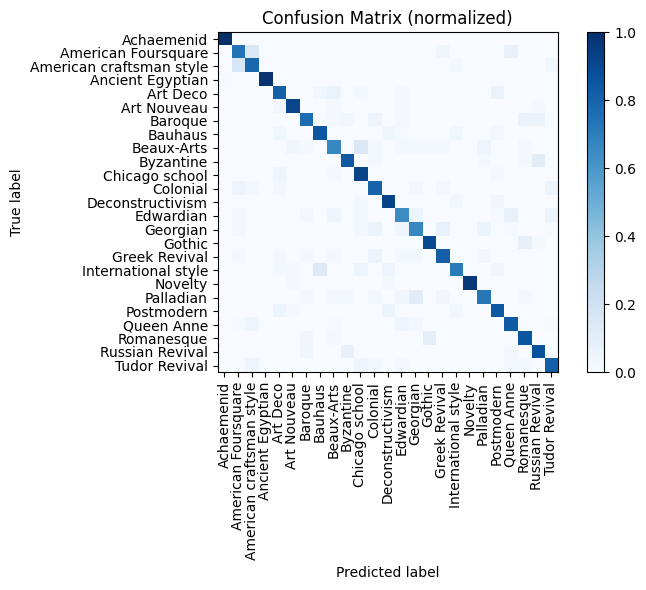

/tmp/ipython-input-281480997.py:120: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "Timestamp": datetime.utcnow().isoformat(),


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Macro-F1,Top-5 Acc,Balanced Acc,Classes,Batch size
0,2025-08-28T09:36:46.706110,ViT-L-16-SigLIP2-384,webli,Linear probe only (valid),LR[lbfgs/l2/multinomial],0.8262,0.8235,0.9874,0.8268,25,64


Saved CSV to: /content/lp_ensemble_eval_results.csv and /content/drive/MyDrive/ArchiStyles-2/lp_ensemble_eval_results.csv


In [ ]:
#per la confusion matrix devo ricalcolare  L e le altre metriche perchè sono definite solo lì sono un pirla , ci ha mesos troppo tempo per rifarlo
# === Analisi + Confusion Matrix + Salvataggio CSV (pronto per Colab) ===
import os, numpy as np, torch, matplotlib.pyplot as plt, pandas as pd
from datetime import datetime
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    top_k_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    balanced_accuracy_score
)
from torchvision.datasets import ImageFolder
from torchvision import transforms

# -------------------------
# 1) Caricamento cache e classi
# -------------------------
data_root = prepare_data_root()  # stessa funzione del tuo script

Xp_tr, yp_tr = cache_paths(data_root, CFG.TRAIN_SPLIT)
Xp_ev, yp_ev = cache_paths(data_root, CFG.EVAL_SPLIT)

assert all(os.path.exists(p) for p in [Xp_tr, yp_tr, Xp_ev, yp_ev]), \
    "Cache non trovata. Esegui prima lo script principale per generare X_*.npy / y_*.npy."

Xtr, ytr = np.load(Xp_tr), np.load(yp_tr)
Xev, yev = np.load(Xp_ev), np.load(yp_ev)

# Recupero classi nell'ordine corretto (ImageFolder)
_dummy_tf = transforms.Compose([transforms.Resize((2,2)), transforms.ToTensor()])
classnames = ImageFolder(os.path.join(data_root, CFG.TRAIN_SPLIT), transform=_dummy_tf).classes

# -------------------------
# 2) Logistic Regression (rialleno qui, no helper)
# -------------------------
solver = CFG.LR_SOLVER
multi  = CFG.LR_MULTI_CLASS if solver != "liblinear" else "ovr"
pen    = CFG.LR_PENALTY if solver in {"saga","liblinear","lbfgs"} else "l2"

clf = LogisticRegression(
    max_iter=CFG.LR_MAX_ITER,
    solver=solver,
    class_weight='balanced',
    C=CFG.LR_C,
    penalty=pen,
    multi_class=multi,
    n_jobs=-1 if solver == "saga" else None,
)
clf.fit(Xtr, ytr)
L_lp = clf.decision_function(Xev).astype("float32")   # (N,C)

# -------------------------
# 3) (Opzionale) Ensemble con Zero-Shot
# -------------------------
if CFG.USE_ZERO_SHOT_ENSEMBLE:
    model, tokenizer, _ = build_model_and_preprocess()
    L_zs = encode_text_logits(model, tokenizer, classnames, Xev, temperature=CFG.ZERO_SHOT_TEMP)
    L = CFG.ENSEMBLE_ALPHA * L_lp + (1.0 - CFG.ENSEMBLE_ALPHA) * L_zs
    scenario = f"Linear probe + Zero-shot ensemble ({CFG.EVAL_SPLIT})"
    tech = f"LR[{solver}/{pen}/{multi}], α={CFG.ENSEMBLE_ALPHA}, {len(CFG.ZERO_SHOT_TEMPLATES)} prompts"
else:
    L = L_lp
    scenario = f"Linear probe only ({CFG.EVAL_SPLIT})"
    tech = f"LR[{solver}/{pen}/{multi}]"

# Predizioni e probabilità
y_pred = L.argmax(1)
probs  = torch.softmax(torch.tensor(L), dim=1).numpy()

# -------------------------
# 4) Metriche stile "FINE_GRADIENT"
# -------------------------
# 4.1 Accuracy
acc = accuracy_score(yev, y_pred)
print(f"Accuracy: {acc:.4f}")

# 4.2 Macro-F1
macro_f1 = f1_score(yev, y_pred, average="macro")
print(f"Macro-F1: {macro_f1:.4f}")

# 4.3 Balanced Accuracy (utile con classi sbilanciate)
bal_acc = balanced_accuracy_score(yev, y_pred)
print(f"Balanced Acc: {bal_acc:.4f}")

# 4.4 Report dettagliato per classe
print("\nClassification report:\n")
print(classification_report(yev, y_pred, target_names=classnames, digits=4, zero_division=0))

# 4.5 Accuracy@K
for k in [1, 2, 3, 5]:
    if k <= len(classnames):
        topk = top_k_accuracy_score(yev, probs, k=k, labels=range(len(classnames)))
        print(f"Top-{k} Accuracy: {topk:.4f}")

# -------------------------
# 5) Confusion Matrix normalizzata (come nel tuo esempio)
# -------------------------
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true=yev,
    y_pred=y_pred,
    display_labels=classnames,
    normalize="true",       # percentuali per riga
    cmap="Blues",
    include_values=False,   # niente numeri nelle celle
    xticks_rotation=90,
    ax=ax,
    colorbar=True
)
ax.set_title("Confusion Matrix (normalized)")
plt.tight_layout()
plt.show()

# -------------------------
# 6) Salvataggio risultati in CSV (nome diverso)
# -------------------------
# Raccogli i principali indicatori
top5 = top_k_accuracy_score(yev, probs, k=min(5, len(classnames)), labels=range(len(classnames)))

row = {
    "Timestamp": datetime.utcnow().isoformat(),
    "Model": CFG.MODEL_NAME,
    "Pretrained": CFG.PRETRAINED,
    "Scenario": scenario,
    "Techniques": tech,
    "Top-1 Acc": round(float(acc), 4),
    "Macro-F1": round(float(macro_f1), 4),
    "Top-5 Acc": round(float(top5), 4),
    "Balanced Acc": round(float(bal_acc), 4),
    "Classes": int(len(classnames)),
    "Batch size": int(CFG.BATCH_SIZE),
}

df = pd.DataFrame([row])
try:
    from IPython.display import display  # per Colab
    display(df)
except Exception:
    print(df)

# File name aggiornato
csv_name = "lp_ensemble_eval_results.csv"

# Salva in locale
csv_path_local = f"/content/{csv_name}"
if os.path.exists(csv_path_local):
    old = pd.read_csv(csv_path_local)
    out = pd.concat([old, df], ignore_index=True)
else:
    out = df.copy()
out.to_csv(csv_path_local, index=False)

# Salva anche nella cartella del dataset su Drive
csv_path_drive = os.path.join(data_root, csv_name)
try:
    if os.path.exists(csv_path_drive):
        old_d = pd.read_csv(csv_path_drive)
        out_d = pd.concat([old_d, df], ignore_index=True)
    else:
        out_d = df.copy()
    out_d.to_csv(csv_path_drive, index=False)
    print("Saved CSV to:", csv_path_local, "and", csv_path_drive)
except Exception as e:
    print("Saved CSV to:", csv_path_local)
    print("Drive save failed:", e)


In [ ]:
#SALVO I DATI PER LE PROSSIME SESSIONI

# === Salvataggio checkpoint su Drive ===
import joblib

# Percorsi su Drive
save_dir = data_root   # la stessa cartella del dataset su Drive DI BIAGIO CARPANHOUSE
os.makedirs(save_dir, exist_ok=True)

# 1) Modello LogisticRegression
joblib_path = os.path.join(save_dir, "linear_probe.joblib")
joblib.dump(clf, joblib_path)
print("Salvato LogisticRegression in:", joblib_path)

# 2) Logits ensemble e ground truth
np.save(os.path.join(save_dir, "L_eval.npy"), L)
np.save(os.path.join(save_dir, "y_eval.npy"), yev)
print("Salvati logits e y_true in Drive.")

# 3) (opzionale) Predizioni e probabilità
np.save(os.path.join(save_dir, "y_pred.npy"), y_pred)
np.save(os.path.join(save_dir, "probs.npy"), probs)
print("Salvati y_pred e probs in Drive.")

print("\n✅ Tutti i dati principali salvati su Drive.")
print("La prossima volta ti basta caricarli con joblib.load / np.load senza rifare training.")


Salvato LogisticRegression in: /content/drive/MyDrive/ArchiStyles-2/linear_probe.joblib
Salvati logits e y_true in Drive.
Salvati y_pred e probs in Drive.

✅ Tutti i dati principali salvati su Drive.
La prossima volta ti basta caricarli con joblib.load / np.load senza rifare training.


[DATA] Using DATA_ROOT = /content/drive/MyDrive/ArchiStyles-2

=== MIGLIORE: KNN[k=5,distance] ===
Top-1 Acc: 0.8269 | Macro-F1: 0.8240 | BalAcc: 0.8263 | Top-5: 0.9407

Classification report (best):

                          precision    recall  f1-score   support

              Achaemenid     0.9831    0.9831    0.9831        59
     American Foursquare     0.7593    0.7455    0.7523        55
American craftsman style     0.8197    0.8929    0.8547        56
        Ancient Egyptian     0.9853    0.9853    0.9853        68
                Art Deco     0.8596    0.7656    0.8099        64
             Art Nouveau     0.8382    0.9661    0.8976        59
                 Baroque     0.8947    0.7969    0.8430        64
                 Bauhaus     0.8462    0.8250    0.8354        80
              Beaux-Arts     0.7963    0.6825    0.7350        63
               Byzantine     0.8169    0.9355    0.8722        62
          Chicago school     0.7231    0.9400    0.8174        50
      

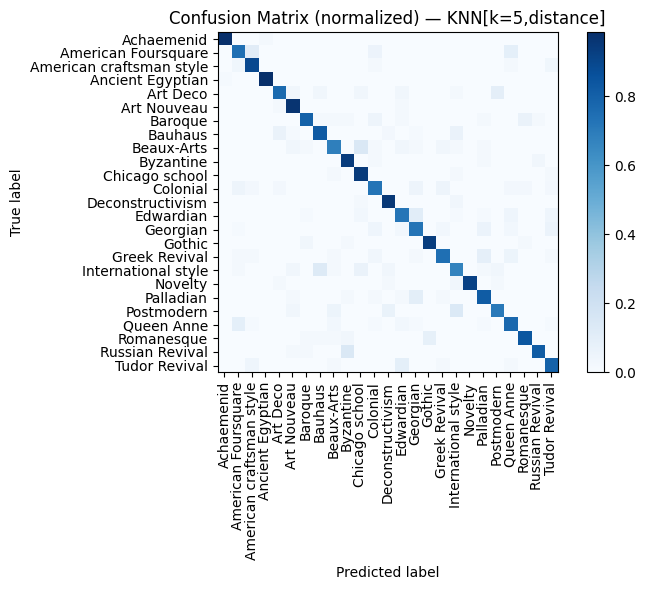

/tmp/ipython-input-49533008.py:157: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "Timestamp": datetime.utcnow().isoformat(),


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Macro-F1,Top-5 Acc,Balanced Acc,Classes,Batch size
0,2025-08-28T10:12:45.098355,ViT-L-16-SigLIP2-384,webli,"KNN[k=5,distance] (valid)",Scaler,0.8269,0.824,0.9407,0.8263,25,64


Saved CSV to: /content/lp_alt_probes_eval_results.csv and /content/drive/MyDrive/ArchiStyles-2/lp_alt_probes_eval_results.csv


In [ ]:
'''
NON devi ri-passare le immagini
Per provare SVM o KNN ti basta riusare gli embedding già salvati (X_*.npy, y_*.npy)
e riallenare un nuovo “linear probe” sullo spazio degli embedding.

'''
# === SVM / KNN Linear Probe sugli embedding CLIP (fix: no dict mutation during iteration) ===
import os, numpy as np, torch, matplotlib.pyplot as plt, pandas as pd
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, balanced_accuracy_score,
    top_k_accuracy_score, classification_report,
    ConfusionMatrixDisplay
)
from torchvision.datasets import ImageFolder
from torchvision import transforms

# -------------------------
# Toggle / Hyperparam
# -------------------------
USE_PCA = False
PCA_DIM = 512

RUN_LINEAR_SVM = True
RUN_RBF_SVM   = False
RUN_KNN       = True

LINEAR_SVM_C = 1.0
RBF_SVM_C    = 2.0
RBF_SVM_G    = 'scale'

KNN_K        = 5
KNN_WEIGHTS  = 'distance'
KNN_LEAF     = 30

USE_ZERO_SHOT_ENSEMBLE = CFG.USE_ZERO_SHOT_ENSEMBLE
ZS_TEMP   = CFG.ZERO_SHOT_TEMP
ALPHA     = 0.5

# -------------------------
# 1) Caricamento cache e classi
# -------------------------
data_root = prepare_data_root()
Xp_tr, yp_tr = cache_paths(data_root, CFG.TRAIN_SPLIT)
Xp_ev, yp_ev = cache_paths(data_root, CFG.EVAL_SPLIT)
assert all(os.path.exists(p) for p in [Xp_tr, yp_tr, Xp_ev, yp_ev]), "Cache mancante."

Xtr, ytr = np.load(Xp_tr), np.load(yp_tr)
Xev, yev = np.load(Xp_ev), np.load(yp_ev)

_dummy_tf = transforms.Compose([transforms.Resize((2,2)), transforms.ToTensor()])
classnames = ImageFolder(os.path.join(data_root, CFG.TRAIN_SPLIT), transform=_dummy_tf).classes
n_classes = len(classnames)

# -------------------------
# 2) Preprocess (Scaler + opzionale PCA)
# -------------------------
scaler = StandardScaler().fit(Xtr)
Xtr_p = scaler.transform(Xtr)
Xev_p = scaler.transform(Xev)

if USE_PCA:
    pca = PCA(n_components=PCA_DIM, svd_solver='auto', random_state=CFG.SEED).fit(Xtr_p)
    Xtr_p = pca.transform(Xtr_p)
    Xev_p = pca.transform(Xev_p)

# -------------------------
# Helpers
# -------------------------
def scores_to_metrics(scores):
    """scores -> dict con metriche e artefatti utili"""
    y_pred = scores.argmax(1)
    probs  = torch.softmax(torch.tensor(scores), dim=1).numpy()
    return dict(
        acc=accuracy_score(yev, y_pred),
        macro_f1=f1_score(yev, y_pred, average="macro"),
        bal_acc=balanced_accuracy_score(yev, y_pred),
        top5=top_k_accuracy_score(yev, probs, k=min(5, n_classes), labels=range(n_classes)),
        y_pred=y_pred, probs=probs, scores=scores
    )

# -------------------------
# 3) Modelli base
# -------------------------
candidates = {}  # non sarà modificato mentre lo iteriamo

if RUN_LINEAR_SVM:
    lin = LinearSVC(C=LINEAR_SVM_C, class_weight='balanced', dual="auto", max_iter=50000, random_state=CFG.SEED)
    lin.fit(Xtr_p, ytr)
    L_lin = lin.decision_function(Xev_p).astype("float32")
    candidates[f"LinearSVM[C={LINEAR_SVM_C}]"] = scores_to_metrics(L_lin)

if RUN_RBF_SVM:
    rbf = SVC(C=RBF_SVM_C, kernel='rbf', gamma=RBF_SVM_G, class_weight='balanced', probability=False, random_state=CFG.SEED)
    rbf.fit(Xtr_p, ytr)
    L_rbf = rbf.decision_function(Xev_p).astype("float32")
    candidates[f"RBF-SVM[C={RBF_SVM_C},γ={RBF_SVM_G}]"] = scores_to_metrics(L_rbf)

if RUN_KNN:
    knn = KNeighborsClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS, leaf_size=KNN_LEAF, n_jobs=-1)
    knn.fit(Xtr_p, ytr)
    probs_knn = knn.predict_proba(Xev_p)  # (N, C_presenti)
    L_knn = np.zeros((Xev_p.shape[0], n_classes), dtype=np.float32)
    for cls_idx, cls_label in enumerate(knn.classes_):
        L_knn[:, cls_label] = probs_knn[:, cls_idx]
    # log-probs come "scores"
    eps = 1e-9
    L_knn = np.log(L_knn + eps).astype("float32")
    candidates[f"KNN[k={KNN_K},{KNN_WEIGHTS}]"] = scores_to_metrics(L_knn)

# -------------------------
# 4) Zero-Shot Ensemble (senza modificare il dict durante l'iterazione)
# -------------------------
all_models = dict(candidates)  # copia separata
if USE_ZERO_SHOT_ENSEMBLE:
    model, tokenizer, _ = build_model_and_preprocess()
    L_zs = encode_text_logits(model, tokenizer, classnames, Xev, temperature=ZS_TEMP)
    for name, res in list(candidates.items()):  # lista statica di item
        L_ens = ALPHA * res['scores'] + (1.0 - ALPHA) * L_zs
        all_models[name + " + ZS"] = scores_to_metrics(L_ens)

# -------------------------
# 5) Scegli il migliore
# -------------------------
best_name, best = max(all_models.items(), key=lambda kv: kv[1]['acc'])
print(f"\n=== MIGLIORE: {best_name} ===")
print(f"Top-1 Acc: {best['acc']:.4f} | Macro-F1: {best['macro_f1']:.4f} | BalAcc: {best['bal_acc']:.4f} | Top-5: {best['top5']:.4f}\n")
print("Classification report (best):\n")
print(classification_report(yev, best['y_pred'], target_names=classnames, digits=4, zero_division=0))

# -------------------------
# 6) Confusion Matrix del migliore
# -------------------------
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true=yev, y_pred=best['y_pred'],
    display_labels=classnames, normalize="true",
    cmap="Blues", include_values=False, xticks_rotation=90, ax=ax, colorbar=True
)
ax.set_title(f"Confusion Matrix (normalized) — {best_name}")
plt.tight_layout(); plt.show()

# -------------------------
# 7) (Opzionale) Salva artefatti del migliore
# -------------------------
np.save(os.path.join(data_root, "L_eval_best.npy"), best['scores'])
np.save(os.path.join(data_root, "y_eval.npy"), yev)
np.save(os.path.join(data_root, "y_pred_best.npy"), best['y_pred'])
np.save(os.path.join(data_root, "probs_best.npy"), best['probs'])

# Log CSV
row = {
    "Timestamp": datetime.utcnow().isoformat(),
    "Model": CFG.MODEL_NAME,
    "Pretrained": CFG.PRETRAINED,
    "Scenario": f"{best_name} ({CFG.EVAL_SPLIT})",
    "Techniques": f"Scaler{' + PCA' if USE_PCA else ''}",
    "Top-1 Acc": round(float(best['acc']), 4),
    "Macro-F1": round(float(best['macro_f1']), 4),
    "Top-5 Acc": round(float(best['top5']), 4),
    "Balanced Acc": round(float(best['bal_acc']), 4),
    "Classes": int(n_classes),
    "Batch size": int(CFG.BATCH_SIZE),
}
df = pd.DataFrame([row])
from IPython.display import display; display(df)

csv_name  = "lp_alt_probes_eval_results.csv"
csv_local = f"/content/{csv_name}"
if os.path.exists(csv_local):
    old = pd.read_csv(csv_local); out = pd.concat([old, df], ignore_index=True)
else:
    out = df.copy()
out.to_csv(csv_local, index=False)

csv_drive = os.path.join(data_root, csv_name)
try:
    if os.path.exists(csv_drive):
        old_d = pd.read_csv(csv_drive); out_d = pd.concat([old_d, df], ignore_index=True)
    else:
        out_d = df.copy()
    out_d.to_csv(csv_drive, index=False)
    print("Saved CSV to:", csv_local, "and", csv_drive)
except Exception as e:
    print("Saved CSV to:", csv_local)
    print("Drive save failed:", e)
